# EDA del banco piloto de consultas

Fuente: `data/processed/question_bank/consultas_piloto.csv`.

In [1]:
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

import pandas as pd
import matplotlib.pyplot as plt

QB = ROOT / "data" / "processed" / "question_bank" / "consultas_piloto.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
qb = pd.read_csv(QB)
qb.head()


,query_id,pregunta,categoria,complejidad,doc_referencia,seccion_referencia,respuesta_esperada,requiere_herramienta,requiere_multiples_fuentes,es_respondible,validacion_experta,candidate_strategy,origen
0,Q001,¿Qué modalidades de estudio tiene la UMA?,N,baja,D012,NaN,"Presencial, Semipresencial y A Distancia; varí...",False,False,True,draft,A1,faq
1,Q002,¿Pueden deshabilitarme por inasistencias?,N,media,D012,NaN,Hasta 30% de inasistencias a sesiones con hora...,False,False,True,draft,A1,faq
2,Q003,¿Qué es el examen sustitutorio y quiénes puede...,N,media,D012,NaN,Evaluación extraordinaria opcional que reempla...,False,False,True,draft,A1,faq
3,Q004,¿En qué consiste el curso o examen de aplazados?,N,alta,D012,NaN,Trámite para recuperar asignaturas desaprobada...,False,False,True,draft,A1,faq
4,Q005,¿Dónde reviso mis horarios de clase actualizados?,A,baja,D012,NaN,"En SIGU, opción matrícula.",False,False,True,draft,A5,faq


## Distribución por categoría y complejidad

categoria (N/R/M/A):


categoria
A     44
M     11
N    125
R     16
Name: count, dtype: int64

complejidad:


complejidad
baja     107
media     65
alta      24
Name: count, dtype: int64

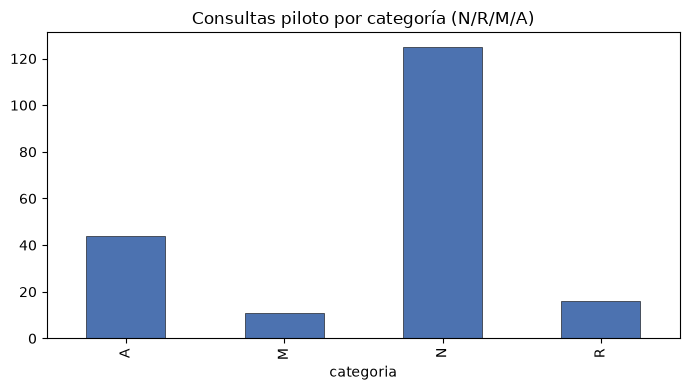

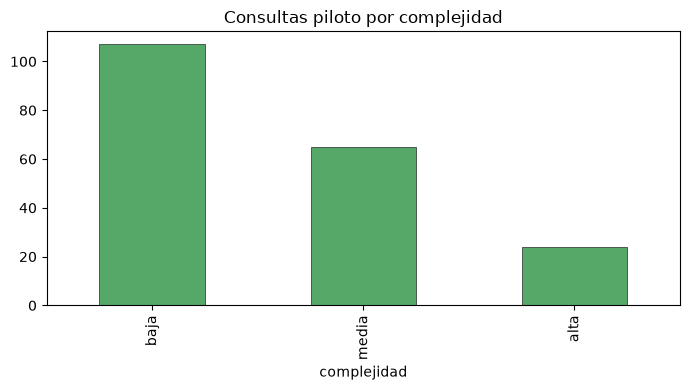

In [2]:
print("categoria (N/R/M/A):")
display(qb["categoria"].value_counts().sort_index())
print("complejidad:")
display(qb["complejidad"].value_counts())

by_cat = qb["categoria"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
by_cat.plot(kind="bar", ax=ax, color="#4C72B0", edgecolor="black", linewidth=0.4)
ax.set_title("Consultas piloto por categoría (N/R/M/A)")
ax.set_xlabel("categoria")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_qb_categoria.png", dpi=140)
plt.show()

by_comp = qb["complejidad"].value_counts()
fig2, ax2 = plt.subplots(figsize=(7, 4))
by_comp.plot(kind="bar", ax=ax2, color="#55A868", edgecolor="black", linewidth=0.4)
ax2.set_title("Consultas piloto por complejidad")
ax2.set_xlabel("complejidad")
fig2.tight_layout()
fig2.savefig(FIG_DIR / "eda_qb_complejidad.png", dpi=140)
plt.show()


## Flags de diseño

In [3]:
def _as_bool(series: pd.Series) -> pd.Series:
    return series.astype(str).str.lower().isin(["true", "1", "yes"])

for col in ("requiere_herramienta", "requiere_multiples_fuentes", "es_respondible"):
    print(f"{col}: {int(_as_bool(qb[col]).sum())} / {len(qb)}")
print("validacion_experta:")
display(qb["validacion_experta"].value_counts())


requiere_herramienta: 16 / 196
requiere_multiples_fuentes: 11 / 196
es_respondible: 193 / 196
validacion_experta:


validacion_experta
draft    196
Name: count, dtype: int64

## Cobertura por `doc_referencia`

doc_referencia
D012                       126
D001                        11
D005                         9
D002                         9
D003                         5
D004                         5
D006                         5
D007                         5
D008                         5
D009                         5
D011                         4
malla_demo_grafo             4
pendiente_calendario         1
pendiente_malla_oficial      1
D010                         1
Name: count, dtype: int64

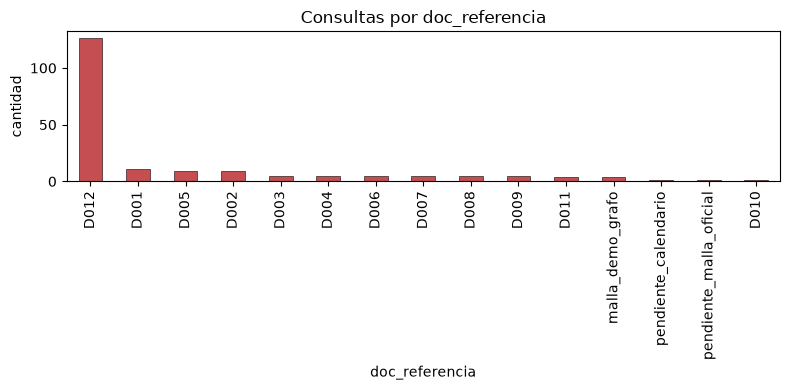

In [4]:
ref = qb["doc_referencia"].fillna("(vacío)").value_counts()
display(ref)
ref.plot(kind="bar", figsize=(8, 4), color="#C44E52", edgecolor="black", linewidth=0.4)
plt.title("Consultas por doc_referencia")
plt.xlabel("doc_referencia")
plt.ylabel("cantidad")
plt.tight_layout()
plt.show()


## `candidate_strategy`

In [5]:
display(qb["candidate_strategy"].value_counts())


candidate_strategy
A1    125
A5     44
A3     27
Name: count, dtype: int64

## Consultas sintéticas desde FAQ

In [6]:
faq_path = ROOT / "data" / "synthetic" / "generated_questions" / "consultas_desde_faq.csv"
if faq_path.exists():
    faq = pd.read_csv(faq_path)
    print(f"consultas_desde_faq.csv: {len(faq)} filas")
    display(faq.head(3))
else:
    print(f"No encontrado: {faq_path}")


consultas_desde_faq.csv: 122 filas


,query_id,pregunta,doc_referencia,validacion_experta,nota
0,S001,¿Cuándo inicia el Proceso 2025-2?,D012,draft,Extraída de FAQ HTML; sin respuesta de referen...
1,S002,¿Qué modalidades de estudio tiene la UMA?,D012,draft,Extraída de FAQ HTML; sin respuesta de referen...
2,S003,¿Qué opciones de pago tengo?,D012,draft,Extraída de FAQ HTML; sin respuesta de referen...


## Conclusiones

- **196 consultas** tipadas: N 125, A 44, R 16, M 11. El piloto ya permite plantear las cuatro vías del enrutamiento, pero está sesgado a norma (N) porque el corpus público es normativo.
- Complejidad: mayoría baja/media (107+65). Sirve para un primer banco de trabajo; las altas (24) son el núcleo difícil (condiciones encadenadas o multi-fuente).
- **Anclaje:** ~126 preguntas cuelgan de D012 (FAQ). Eso es útil (preguntas frecuentes reales), pero también un riesgo: si el índice solo «memoriza» FAQ y no reglamentos, el sistema se ve bien en piloto y falla cuando la FAQ diverja del reglamento.
- Todo el banco está en **`draft`**. No es gold de secretaría.
- `es_respondible`: **193/196** con ancla en corpus usable; quedan fuera pendientes y D010. Ancla ≠ gold de respuesta ya redactado.

| Decisión | Por qué |
|----------|--------|
| Evaluar A0–A5 **estratificado** por categoría N/R/M/A | El desbalance (mucho N) distorsiona un score único |
| Incluir siempre un bloque de preguntas ancladas a reglamentos (D001–D009, D011), no solo FAQ | Evitar sobreajuste a D012 |
| Mantener R y M aunque sean pocas; no inflarlas con inventos | Mejor pocas con evidencia que muchas sin documento |
| Completar `respuesta_esperada` vacías con extracto revisado (sobre todo fuera de FAQ) | Ancla documental ≠ respuesta gold lista |
| Separar en el informe: banco de diseño vs gold validado | `draft` no se vende como muestra representativa |
| Priorizar validación humana en un subconjunto (p. ej. 40–50) antes de subir a 300–500 | Calidad de etiqueta > volumen ciego |

### Insight

El banco confirma la **heterogeneidad de consultas**: no todo es recuperación de párrafo. Hay un bloque claro de derivación (A) y un bloque pequeño pero crítico de herramienta/multi-fuente (R/M). El cuello de botella actual no es «faltan preguntas», sino **etiquetado coherente + evidencia institucional** para R y fechas.

